<div align="center">
  <img src="https://capsule-render.vercel.app/api?type=waving&color=0:0f2027,50:203a43,100:2c5364&height=200&section=header&text=Deep%Learning%20Projet&fontSize=50&fontColor=ffffff&animation=fadeIn&fontAlignY=38&desc=Fall%20Semester%202026/2027&descAlignY=58&descSize=18" width="100%" alt="banner"/>
</div>

In [1]:
import pandas as pd
import tensorflow as tf
import os
import matplotlib.pyplot as plt
import numpy as np
import sklearn
from sklearn.model_selection import train_test_split

import torch
import torchvision
import cleanlab
import tqdm

c:\Users\tiago\anaconda3\envs\ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
labels_df = pd.read_csv("../Data/labels_with_hashes.csv")

In [3]:
labels_df.head()

,filename,class_id,description,hash,is_duplicate,n_labels
0,image_000001.JPEG,n03042490,cliff dwelling,4ea329c01903cc77177c0b62d6450784,False,1
1,image_000002.JPEG,n02793495,barn,d2e5e3766f67841827c73fdd234d69e6,False,1
2,image_000003.JPEG,n02793495,barn,441d7c58b3d4abaa7b1644340315dac1,False,1
3,image_000004.JPEG,n02793495,barn,fd0ba89ab10f1326d13019a5b63c3f1a,False,1
4,image_000005.JPEG,n02793495,barn,5332763e5065dde58d0ac261b0c53504,False,1


## **Data Cleaning**

This section will focus on dealing with the previously identified duplicate images and correcting the incorrect labels previously identified on the EDA notebook.

#### **Duplicate Handling**

In [4]:
labels_df_duplicates = labels_df[labels_df["is_duplicate"]]

labels_df_duplicates

,filename,class_id,description,hash,is_duplicate,n_labels
593,image_000594.JPEG,n03891332,parking meter,37bfb8e5b32c68152bfc8d2c7a53ee0b,True,2
1090,image_001091.JPEG,n07749582,lemon,59f2a108dfe8ec55424f514f2ff96a1c,True,2
11907,image_011908.JPEG,n01950731,"sea slug, nudibranch",3a7055e30d47b66c38cf3872564d9ddc,True,2
13623,image_013624.JPEG,n07747607,orange,37bfb8e5b32c68152bfc8d2c7a53ee0b,True,2
15109,image_015110.JPEG,n03584254,iPod,55985fcb729f347a8edf056fa147fb07,True,2
27766,image_027767.JPEG,n03404251,fur coat,0f400b529da4df75a409602c4c5e7db8,True,2
30312,image_030313.JPEG,n01945685,slug,3a7055e30d47b66c38cf3872564d9ddc,True,2
33613,image_033614.JPEG,n01984695,"spiny lobster, langouste, rock lobster, crawfi...",eb57816265bf1eb296181540fe6c2e27,True,2
40382,image_040383.JPEG,n01983481,"American lobster, Northern lobster, Maine lobs...",eb57816265bf1eb296181540fe6c2e27,True,2
47291,image_047292.JPEG,n02988304,CD player,0f400b529da4df75a409602c4c5e7db8,True,2


From the EDA notebook, we concluded that:

- Images with index 27766 and 47291 are the same but have two very different labels. As the image with index 47291 has a label that does not make any sense we're going to **drop that row.**
- Images with index 593 and 13623 are the same but the image with index 593 has a label that does not make sense, so we're also going to **drop that row.**

In images with index 1090 and 59133, we can see lemons and bananas, but for the first image the description is "lemon" and for the second is "banana". We have some options of what to do here: 
-  If there is already an existent description "lemon", "banana", we will keep one of the images and change its description to the existent one;
 - If there isn't an existent description, we cannot just remove one image, because both descriptions are correct, and if we keep just one image, the description will continue to be wrong and we cannot either keep one image, and change the description to "lemon, banana" because in that way we would be creating a new description just for this image.

    So, first, lets check what descriptions already exist.

In [5]:
labels_df.loc[labels_df["description"].str.contains("lemon"), "description"].value_counts()

description
lemon    543
Name: count, dtype: int64

In [6]:
labels_df.loc[labels_df["description"].str.contains("banana"), "description"].value_counts()

description
banana    108
Name: count, dtype: int64

As we can observe from the code above, we have a description called "lemon" and another one called "banana". However, we **do not have the "lemon, banana" description**, therefore, we **decide to remove these two images from the dataset**.

**So far**, we have six pairs of duplicates and **three have already been  assessed**.

About images with index 15109 and 48341, the first image's description is iPod and the other is sock. From the image, analyzed in the EDA notebook, our position is that it is an iPod inside a sock. In that sense, we are **going to drop those two rows too**.

In [7]:
labels_df.loc[labels_df["description"].str.contains("iPod"), "description"].value_counts()

description
iPod    532
Name: count, dtype: int64

In [8]:
labels_df.loc[labels_df["description"].str.contains("sock"), "description"].value_counts()

description
sock    198
Name: count, dtype: int64

**4 out of 6 pairs assessed**

The images with index 33613 and 40382 are not very clear and both have descriptions make sense as they are both related to the ocean. The descriptions are:
- "spiny lobster, langouste, rock lobster, crawfish, crayfish, sea crawfish
- "American lobster, Northern lobster, Maine lobster, Homarus americanus"

In [9]:
labels_df.loc[labels_df["description"].str.contains("spiny lobster, langouste, rock lobster, crawfish, crayfish, sea crawfish"), "description"].value_counts()

description
spiny lobster, langouste, rock lobster, crawfish, crayfish, sea crawfish    347
Name: count, dtype: int64

In [10]:
labels_df.loc[labels_df["description"].str.contains("American lobster, Northern lobster, Maine lobster, Homarus americanus"),"description"].value_counts()

description
American lobster, Northern lobster, Maine lobster, Homarus americanus    353
Name: count, dtype: int64

Since we cannot distinguish from the photo what the correct description is we are **going to drop both of the rows**.

**5 out of 6 pairs assessed**

Lastly, the images with index 11907 and 30312 have the descriptions "sea slug, nudibranch" and "slug" respectively. We consider this as a special case and, therefore, we're going to see more 5 images of each description to evaluate what image we remove.

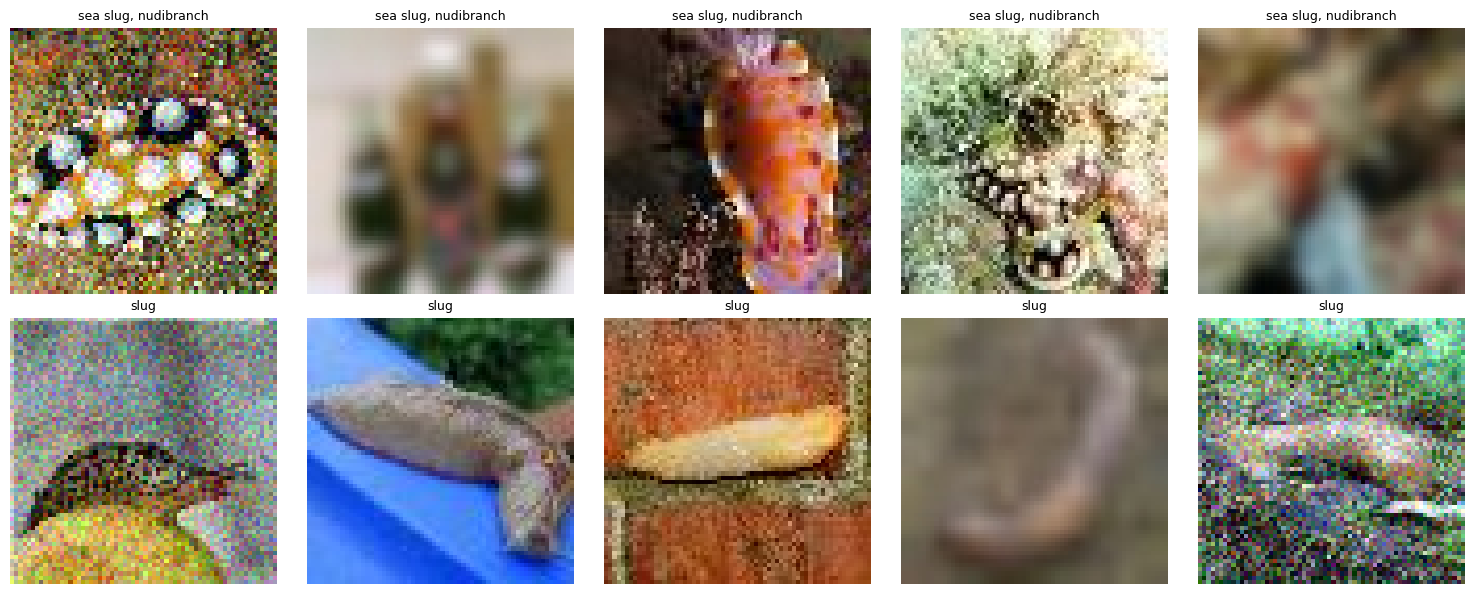

In [11]:
path = "../Data/Tiny_ImageNet_Project_2026_Students/images"

def get_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = image / 255
    return image

# Select 5 random non-duplicate images from each class
sea_slugs = labels_df[
    (labels_df["description"] == "sea slug, nudibranch") &
    (~labels_df["is_duplicate"])
].sample(n=5, random_state=42)

slugs = labels_df[
    (labels_df["description"] == "slug") &
    (~labels_df["is_duplicate"])
].sample(n=5, random_state=42)

selected_images = pd.concat([sea_slugs, slugs])

# Display images using the same approach as EDA
plt.figure(figsize=(15, 6))

for i, (_, dataset_row) in enumerate(selected_images.iterrows()):
    image = get_image(os.path.join(path, dataset_row["filename"]))

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(dataset_row["description"], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


Since these extra images were not that helpful because they're very different from the images of the dilemma and since, in ourp erspective, the background of the images of the dilemma does not look like underwater/ocean, we are going to remove the image with the description "sea slug, nudibranch" with index 11907.

Therefore, **all the six pairs of duplicates have been addressed**.

To summarize, the index of rows we're going to drop are:
- 47291
- 593
- 1090
- 59133
- 15109
- 48341
- 33613
- 40382
- 11907

In [12]:
indices_to_drop = [47291,593,1090,59133,15109,48341,33613,40382,11907] #remover pelo filename em vez de ser pelo indice

labels_df = labels_df.drop(indices_to_drop)

In [13]:
print("Remaining images:", len(labels_df))
print("Remaining duplicates:", labels_df["hash"].duplicated(keep=False).sum())

Remaining images: 59991
Remaining duplicates: 0


In [14]:
labels_df["is_duplicate"] = labels_df["hash"].duplicated(keep=False)

labels_df[labels_df["is_duplicate"] == True]

,filename,class_id,description,hash,is_duplicate,n_labels


#### **Incorrect Label Correction**

## **Data Splitting**

Dividing the dataset in Train, Validation and Test set in order to avoid data leakage.

In [15]:
labels_df.groupby("class_id")["description"].nunique().max()

1

As one class_id corresponds to one only label/description, we are going to stratify on `class_id`.

## **Image Transformations**

As previously observed in the EDA notebook, all the images have the same size, so we do not need to resize the images. This sections will focus on the normalization, which consists of, for each pixel, change the [0,255] range to [0,1], and convert each image to a tensor.

#### **Image Normalization**

#### **Converting each image to a tensor**

## **Data Augmentation & Class Imbalance Handling**

Through transformations such as, rotations, we will increase the amount of training data. This is specially useful in this case, as it is a way to decrease class imbalance, by focusing on Class-Specific Data Agumentation, where we apply augmentation more frequently to the minority classes.